# Half-Eye Plot (Density + Intervals)

**Family:** Uncertainty &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Uncertainty:* Show what is not known (intervals, probabilities and possible outcomes) so readers do not over-trust a single number.

## Design purpose

Combines a half-violin density (the shape of the uncertainty) with a point estimate and two nested intervals beneath it: a thick 66% interval and a thin 95% interval. It shows the full distribution and conventional summaries in one compact mark, and is common for Bayesian posteriors and bootstrap distributions.

## When to use

- Show posterior or bootstrap distributions for several groups or parameters
- Distributions may be skewed, and a symmetric error bar would misrepresent them
- Combine intuitive shape with precise interval endpoints

## Avoid when

- The audience is unfamiliar with intervals and densities (use an icon array or quantile dotplot)
- You have raw observations rather than uncertainty about an estimate (use a raincloud plot)

## Alternatives

- Forest plot (intervals only)
- Gradient interval
- Violin plot

## Design tips

- Explain the two interval widths in a legend or caption
- Draw a reference line (zero effect, target) when there is one
- Order the groups by median unless they have a natural order

## Example

Posterior distributions of the reduction in systolic blood pressure (mmHg) for four interventions, from simulated MCMC draws. Some are skewed.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from scipy.stats import gaussian_kde

### Data

In [2]:
rng = np.random.default_rng(21)
n = 4000
draws = pd.DataFrame({
    "Exercise programme": rng.normal(4.5, 1.6, n),
    "Salt reduction": rng.normal(3.2, 1.3, n),
    "App-based coaching": rng.gamma(1.6, 1.5, n) - 0.6,
    "Medication": rng.normal(9.0, 1.4, n),
})
summary = draws.quantile([0.025, 0.17, 0.5, 0.83, 0.975]).T.round(1)
summary.columns = ["2.5%", "17%", "median", "83%", "97.5%"]
order = summary["median"].sort_values().index
summary.loc[order]

,2.5%,17%,median,83%,97.5%
App-based coaching,-0.4,0.2,1.3,3.3,6.4
Salt reduction,0.6,1.9,3.2,4.5,5.7
Exercise programme,1.4,3.0,4.5,6.0,7.6
Medication,6.2,7.7,9.0,10.3,11.7


### Plot

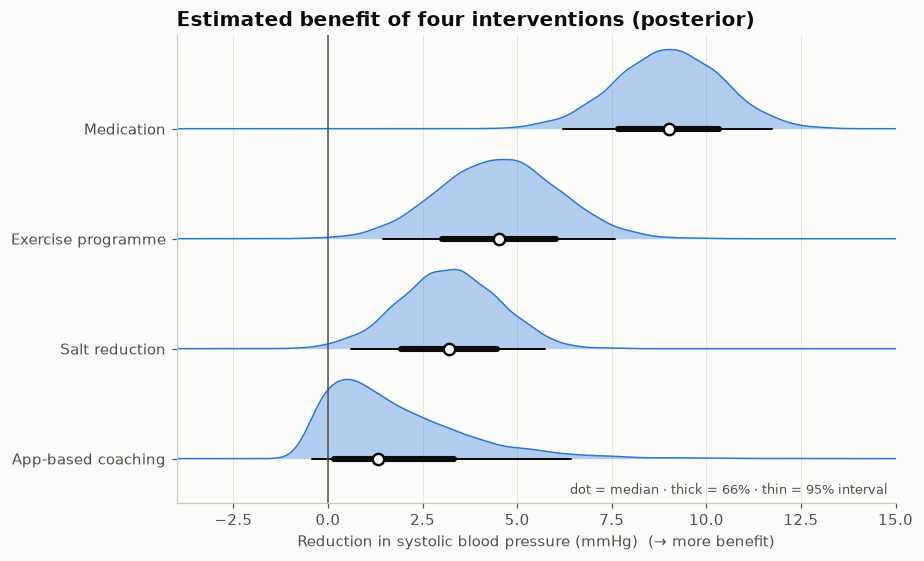

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
xs = np.linspace(-4, 15, 500)
for i, name in enumerate(order):
    v = draws[name].values
    dens = gaussian_kde(v)(xs)
    dens = dens / dens.max() * 0.72
    ax.fill_between(xs, i, i + dens, color=PALETTE[0], alpha=0.35, linewidth=0)
    ax.plot(xs, i + dens, color=PALETTE[0], lw=1)
    lo95, lo66, med, hi66, hi95 = np.quantile(v, [0.025, 0.17, 0.5, 0.83, 0.975])
    ax.plot([lo95, hi95], [i, i], color="#0b0b0b", lw=1.3, solid_capstyle="round")
    ax.plot([lo66, hi66], [i, i], color="#0b0b0b", lw=4, solid_capstyle="round")
    ax.scatter([med], [i], s=55, color="#fcfcfb", edgecolor="#0b0b0b", linewidth=1.6, zorder=4)
ax.axvline(0, color="#52514e", lw=1)
ax.set_yticks(range(len(order)), order)
ax.set_ylim(-0.4, len(order) - 0.15)
ax.set_xlim(-4, 15)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Reduction in systolic blood pressure (mmHg)  (→ more benefit)")
ax.set_title("Estimated benefit of four interventions (posterior)")
ax.text(14.8, -0.32, "dot = median · thick = 66% · thin = 95% interval", ha="right",
        fontsize=8.5, color="#52514e")
fig.tight_layout()
plt.show()

## How to read it

The dot is the median, the thick bar holds the middle 66% of plausible values, and the thin bar holds 95%. Medication clearly lowers blood pressure (all of its 95% interval is above 0). Salt reduction is very likely beneficial. The app-based coaching posterior is wide and right-skewed: it might do a lot or almost nothing.

---
Standalone script: [`half_eye.py`](half_eye.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)